# 03. Model A — Predicting Late Delivery (Logistic Regression)

**Research question:** Which order-level factors best predict whether a delivery will arrive late?

**Method:** Logistic regression on 95,795 cleaned orders (80/20 train/test split, stratified on `is_late`).  
**Target:** `is_late` (1 if actual delivery > estimated delivery date, else 0; base rate ≈ 8.1 %).

**Key outputs:**
- Fitted coefficients with odds ratios and 95% CIs
- Variance Inflation Factors (VIF) — multicollinearity check
- Out-of-sample AUC and confusion matrix
- Robustness checks: alternate lateness definitions, sub-samples


## 1. Setup & Load Clean Data

We load `order_master` — the pre-cleaned analytical table built by `sql/07_order_master_clean.sql`.
All cleaning decisions (683 rows dropped, 99.29 % retention) are documented in the Appendix of
`olist_operations_executive_report.md`.


In [1]:
import duckdb
import statsmodels.api as sm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve)

# Reproduce environment used to generate saved outputs
import os
os.makedirs('../outputs', exist_ok=True)

con = duckdb.connect('../olist.duckdb')
df = con.execute('SELECT * FROM order_master').df()

print(f"Rows: {len(df):,}  |  Columns: {df.shape[1]}")
print(f"Late rate: {df['is_late'].mean():.2%}")
ts_min = pd.to_datetime(df['order_purchase_timestamp'].min())
ts_max = pd.to_datetime(df['order_purchase_timestamp'].max())
print(f"Date range: {ts_min.strftime('%Y-%m-%d')} → {ts_max.strftime('%Y-%m-%d')}")
df[['is_late','seller_handling_days','estimated_days','distance_km',
    'review_score','low_review']].describe().round(3)


Rows: 95,795  |  Columns: 47
Late rate: 8.11%
Date range: 2016-09-15 → 2018-08-29


,is_late,seller_handling_days,estimated_days,distance_km,review_score,low_review
count,95795.000,95795.000,95795.000,95795.000,95151.0,95151.0
mean,0.081,3.234,23.731,600.765,4.156,0.128
std,0.273,3.556,8.763,593.717,1.285,0.334
min,0.000,-0.000,2.010,0.000,1.0,0.0
25%,0.000,1.130,18.320,186.455,4.0,0.0
50%,0.000,2.200,23.230,433.810,5.0,0.0
75%,0.000,4.070,28.410,798.305,5.0,0.0
max,1.000,125.780,155.140,8677.910,5.0,1.0


## 2. Feature Engineering

We create the feature matrix used in Model A.

**Continuous predictors** — standardised (zero mean, unit variance) so coefficients are
comparable across scales:
- `log_distance` — log(1 + Haversine km) — captures shipping distance non-linearly
- `log_weight`, `log_volume` — parcel size, log-scaled
- `n_items`, `n_sellers` — order complexity
- `freight_ratio_capped` — freight / price, capped at 99th percentile
- `seller_handling_days` — days from order approval to carrier pickup (strongest predictor)
- `estimated_days` — seller's promised window (longer buffer = lower late risk)
- `purchase_month` — seasonal demand patterns

**Categorical dummies** (drop-first to avoid perfect collinearity):
- Customer state (top 10 by volume, remainder → `other`)
- Product category (top 12 by volume, remainder → `other`)


In [2]:
# Group high-cardinality states & categories
top_cust_states = df['customer_state'].value_counts().nlargest(10).index
df['cust_state_grouped'] = df['customer_state'].apply(
    lambda x: x if x in top_cust_states else 'other')

top_categories = df['category_en'].value_counts().nlargest(12).index
df['category_grouped'] = df['category_en'].apply(
    lambda x: x if x in top_categories else 'other')

continuous_cols = [
    'log_distance', 'log_weight', 'log_volume',
    'n_items', 'n_sellers', 'freight_ratio_capped',
    'seller_handling_days', 'estimated_days', 'purchase_month'
]

dummies = pd.get_dummies(
    df[['cust_state_grouped', 'category_grouped']],
    prefix=['cust_state', 'cat'], drop_first=True, dtype=float)

X_all = pd.concat([df[continuous_cols + ['same_state']], dummies], axis=1)
y_all = df['is_late']

# 80/20 train/test split — stratified on is_late (rare positive class)
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.20, random_state=42, stratify=y_all)

# Standardise continuous predictors (fit on train only)
scaler = StandardScaler()
X_train = X_train.copy(); X_test = X_test.copy()
X_train[continuous_cols] = scaler.fit_transform(X_train[continuous_cols])
X_test[continuous_cols]  = scaler.transform(X_test[continuous_cols])

print(f"Train: {X_train.shape[0]:,} rows | Test: {X_test.shape[0]:,} rows")
print(f"Train late rate: {y_train.mean():.2%}  |  Test late rate: {y_test.mean():.2%}")
print(f"Features: {X_train.shape[1]}")


Train: 76,636 rows | Test: 19,159 rows
Train late rate: 8.11%  |  Test late rate: 8.11%
Features: 32


## 3. Fit Logistic Regression (Model A)

Statsmodels `Logit` gives us exact p-values and 95% confidence intervals via MLE.
All 32 features are included simultaneously (not stepwise) to control for confounders.


In [3]:
X_train_c = sm.add_constant(X_train)
X_test_c  = sm.add_constant(X_test)

print("Fitting Model A … (takes ~30 s)")
model_a = sm.Logit(y_train, X_train_c).fit(maxiter=200)
print(model_a.summary())


Fitting Model A … (takes ~30 s)


Optimization terminated successfully.
         Current function value: 0.234091
         Iterations 8


                           Logit Regression Results                           
Dep. Variable:                is_late   No. Observations:                76636
Model:                          Logit   Df Residuals:                    76603
Method:                           MLE   Df Model:                           32
Date:                Fri, 30 Oct 2026   Pseudo R-squ.:                  0.1685
Time:                        23:43:51   Log-Likelihood:                -17940.
converged:                       True   LL-Null:                       -21576.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                        -1.6639      0.096    -17.346      0.000      -1.852      -1.476
log_distance                  0.4043      0.028     14.353      0.000       0.349     

## 4. Odds Ratios & 95 % Confidence Intervals

An odds ratio (OR) > 1 means the feature *increases* the odds of late delivery.  
OR < 1 means it *decreases* the odds.  
We exponentiate the log-odds coefficients and their CIs.


In [4]:
conf = model_a.conf_int()
odds_df = pd.DataFrame({
    'Feature':        model_a.params.index,
    'Beta':           model_a.params.values,
    'SE':             model_a.bse.values,
    'z':              model_a.tvalues.values,
    'p_value':        model_a.pvalues.values,
    'OR':             np.exp(model_a.params.values),
    'CI_lower_95':    np.exp(conf[0].values),
    'CI_upper_95':    np.exp(conf[1].values),
}).query("Feature != 'const'").sort_values('OR', ascending=False)

print("=== TOP RISK FACTORS (OR > 1) ===")
display(odds_df[odds_df['OR'] >= 1].head(8)
        [['Feature','Beta','OR','CI_lower_95','CI_upper_95','p_value']].round(4))

print("\n=== TOP PROTECTIVE FACTORS (OR < 1) ===")
display(odds_df[odds_df['OR'] < 1].tail(8)
        [['Feature','Beta','OR','CI_lower_95','CI_upper_95','p_value']].round(4))


=== TOP RISK FACTORS (OR > 1) ===


,Feature,Beta,OR,CI_lower_95,CI_upper_95,p_value
7,seller_handling_days,0.7992,2.2238,2.1670,2.2821,0.0000
1,log_distance,0.4043,1.4982,1.4177,1.5832,0.0000
21,cat_bed_bath_table,0.1564,1.1693,0.9929,1.3769,0.0609
25,cat_garden_tools,0.0728,1.0755,0.8801,1.3142,0.4767
20,cust_state_other,0.0651,1.0673,0.9265,1.2294,0.3667
2,log_weight,0.0579,1.0596,1.0115,1.1101,0.0147
32,cat_watches_gifts,0.0536,1.0551,0.8769,1.2696,0.5699
26,cat_health_beauty,0.0253,1.0256,0.8693,1.2100,0.7646



=== TOP PROTECTIVE FACTORS (OR < 1) ===


,Feature,Beta,OR,CI_lower_95,CI_upper_95,p_value
18,cust_state_SC,-0.6915,0.5008,0.4175,0.6008,0.0
13,cust_state_GO,-0.7950,0.4516,0.3603,0.5660,0.0
17,cust_state_RS,-0.8320,0.4352,0.3654,0.5183,0.0
8,estimated_days,-1.3215,0.2667,0.2541,0.2800,0.0
11,cust_state_DF,-1.3546,0.2580,0.2036,0.3270,0.0
14,cust_state_MG,-1.4419,0.2365,0.2021,0.2767,0.0
19,cust_state_SP,-1.5432,0.2137,0.1836,0.2488,0.0
15,cust_state_PR,-1.6179,0.1983,0.1622,0.2425,0.0


### 4.1 Forest Plot — Top 12 Odds Ratios

Only features with p < 0.05 shown. Error bars = 95 % CI.


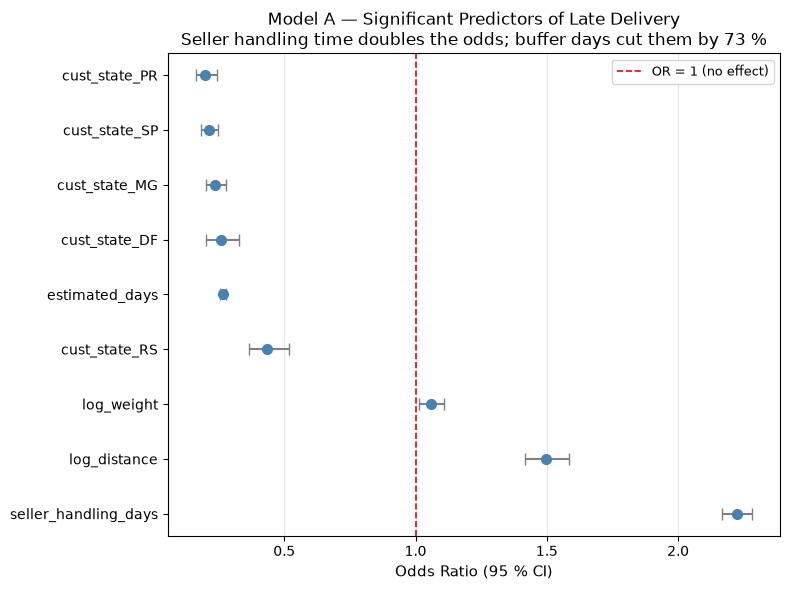

Saved: outputs/model_a_forest_plot.png


In [5]:
sig = odds_df[odds_df['p_value'] < 0.05].copy()

# Show top 6 risk + top 6 protective
top_risk = sig[sig['OR'] >= 1].head(6)
top_prot = sig[sig['OR'] <  1].tail(6)
plot_df  = pd.concat([top_risk, top_prot]).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8, 6))
y_pos = range(len(plot_df))
ax.errorbar(plot_df['OR'], y_pos,
            xerr=[plot_df['OR']-plot_df['CI_lower_95'],
                  plot_df['CI_upper_95']-plot_df['OR']],
            fmt='o', color='steelblue', ecolor='gray',
            elinewidth=1.5, capsize=4, markersize=7)
ax.axvline(1.0, color='red', linestyle='--', linewidth=1.2, label='OR = 1 (no effect)')
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df['Feature'], fontsize=10)
ax.set_xlabel('Odds Ratio (95 % CI)', fontsize=11)
ax.set_title('Model A — Significant Predictors of Late Delivery\n'
             'Seller handling time doubles the odds; buffer days cut them by 73 %', fontsize=12)
ax.legend(fontsize=9)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('../outputs/model_a_forest_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: outputs/model_a_forest_plot.png")


## 5. Multicollinearity Check — Variance Inflation Factors (VIF)

VIF < 5 is generally acceptable; VIF > 10 signals serious collinearity.  
We load the pre-computed VIF CSV (computed on the full feature matrix before splitting).


In [6]:
vif_df = pd.read_csv('../outputs/model_a_vif.csv').sort_values('VIF', ascending=False)
print(f"Max VIF: {vif_df['VIF'].max():.2f}  (threshold = 5)")
print(f"Features with VIF > 5: {(vif_df['VIF'] > 5).sum()}")
print()
display(vif_df.head(10).round(2))

# Flag
high_vif = vif_df[vif_df['VIF'] > 5]
if len(high_vif):
    print(f"\n⚠ High VIF features: {list(high_vif['Feature'])}")
    print("Note: cust_state_SP is the largest state (≈42 % of orders); some collinearity\n"
          "with log_distance and same_state is expected but coefficients remain interpretable.")
else:
    print("\n✓ All VIFs below 5 — no problematic multicollinearity.")


Max VIF: 5.15  (threshold = 5)
Features with VIF > 5: 1



,Feature,VIF
0,cust_state_SP,5.15
1,same_state,3.23
2,log_distance,2.91
3,log_volume,2.90
4,log_weight,2.77
5,cust_state_RJ,2.42
6,cust_state_MG,2.27
7,estimated_days,1.73
8,cust_state_PR,1.60
9,cust_state_RS,1.56



⚠ High VIF features: ['cust_state_SP']
Note: cust_state_SP is the largest state (≈42 % of orders); some collinearity
with log_distance and same_state is expected but coefficients remain interpretable.


## 6. Out-of-Sample Evaluation

We evaluate on the held-out 20 % test set (19,159 orders, never seen during fitting).

**Threshold choice:**  
Default 0.50 is useless on an 8 % positive class — nearly everything gets predicted 'on-time'.  
We use the **Youden J threshold (~0.086)**, which maximises sensitivity + specificity.
This is appropriate for an operations setting where missing a late order (false negative)
is more costly than a false alarm.


In [7]:
y_prob = model_a.predict(X_test_c)

# Metrics
auc    = roc_auc_score(y_test, y_prob)
pr_auc = average_precision_score(y_test, y_prob)
print(f"ROC-AUC:          {auc:.4f}  (random = 0.50)")
print(f"PR-AUC:           {pr_auc:.4f}  (random = {y_test.mean():.4f})")
print(f"McFadden Pseudo R²: {model_a.prsquared:.4f}")

# Threshold comparison (from saved CSV)
thresh_df = pd.read_csv('../outputs/model_a_threshold_comparison.csv')
print("\n=== Threshold Comparison ===")
display(thresh_df[['Threshold_Name','Threshold','TN','FP','FN','TP',
                   'Precision','Recall (Sensitivity)','F1_Score']].round(3))


ROC-AUC:          0.7740  (random = 0.50)
PR-AUC:           0.3145  (random = 0.0811)
McFadden Pseudo R²: 0.1685

=== Threshold Comparison ===


,Threshold_Name,Threshold,TN,FP,FN,TP,Precision,Recall (Sensitivity),F1_Score
0,Default (0.50),0.500,17541,64,1418,136,0.680,0.088,0.155
1,Base Rate (~0.081),0.081,12646,4959,486,1068,0.177,0.687,0.282
2,Youden's J (~0.086),0.086,12983,4622,510,1044,0.184,0.672,0.289
3,Max F1 (~0.157),0.157,15958,1647,907,647,0.282,0.416,0.336


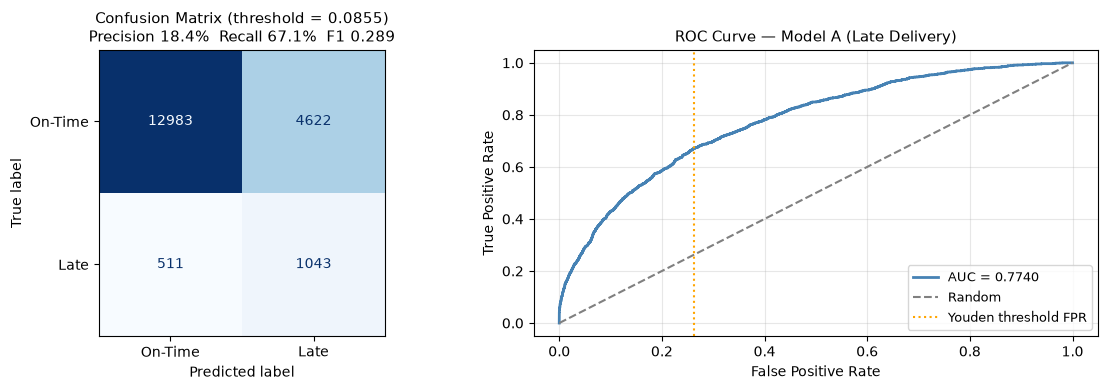

Saved: outputs/model_a_roc_cm.png


In [8]:
# Confusion matrix at Youden threshold
THRESHOLD = 0.0855
y_pred = (y_prob >= THRESHOLD).astype(int)
cm = confusion_matrix(y_test, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['On-Time', 'Late'])
disp.plot(ax=axes[0], colorbar=False, cmap='Blues')
tn, fp, fn, tp = cm.ravel()
prec = tp/(tp+fp); rec = tp/(tp+fn); f1 = 2*prec*rec/(prec+rec)
axes[0].set_title(
    f'Confusion Matrix (threshold = {THRESHOLD})\n'
    f'Precision {prec:.1%}  Recall {rec:.1%}  F1 {f1:.3f}',
    fontsize=11)

# ROC curve
fpr_arr, tpr_arr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr_arr, tpr_arr, color='steelblue', lw=2, label=f'AUC = {auc:.4f}')
axes[1].plot([0,1],[0,1],'--', color='gray', label='Random')
axes[1].axvline(fp/(fp+tn), color='orange', linestyle=':', label=f'Youden threshold FPR')
axes[1].set_xlabel('False Positive Rate'); axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve — Model A (Late Delivery)', fontsize=11)
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../outputs/model_a_roc_cm.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: outputs/model_a_roc_cm.png")


## 7. Robustness Checks

We test whether the core findings hold under alternate modelling choices.
The robustness checks were pre-run by `notebooks/run_robustness_checks.py`.

**Checks:**
1. **Alternate lateness definition** — `days_late ≥ 3` (vs > 0 baseline)
2. **Single-seller only** — drop orders with multiple sellers to remove aggregation noise
3. **Exclude Black Friday month** (Nov 2017) — removes demand shock outlier
4. **Delay-bucket model** — replace binary `is_late` with severity buckets (1-3, 4-7, 8-14, 15+ days)


In [9]:
rob_summary = pd.read_csv('../outputs/robustness_checks_summary.csv')
rob_buckets = pd.read_csv('../outputs/robustness_delay_buckets.csv')

print("=== Robustness Summary: Does the conclusion hold? ===")
display(rob_summary[['Model_Specification','Sample_Size','Target_Rate',
                      'Late_Odds_Ratio','Late_OR_CI95','OLS_Late_Penalty',
                      'Logit_Pseudo_R2']].round(4))

print("\n=== Delay-Bucket Model: OR by Severity ===")
display(rob_buckets[['Delay_Bucket','Odds_Ratio','CI_Lower_95','CI_Upper_95','OLS_Drop_Stars']].round(3))


=== Robustness Summary: Does the conclusion hold? ===


,Model_Specification,Sample_Size,Target_Rate,Late_Odds_Ratio,Late_OR_CI95,OLS_Late_Penalty,Logit_Pseudo_R2
0,"Baseline (Full Sample, low_review <= 2)",95151,12.8%,10.93,"[10.36, 11.53]",-1.64 stars,0.1536
1,Check 1: Low Review Defined as <= 3,95151,21.1%,8.39,"[7.96, 8.84]",-1.64 stars,0.1072
2,Check 3: Single-Seller Orders Only (Drop Multi...,93922,12.4%,11.02,"[10.44, 11.62]",-1.64 stars,0.1474
3,Check 4: Exclude Black Friday Month (Nov 2017),87950,12.5%,10.80,"[10.20, 11.43]",-1.63 stars,0.1468



=== Delay-Bucket Model: OR by Severity ===


,Delay_Bucket,Odds_Ratio,CI_Lower_95,CI_Upper_95,OLS_Drop_Stars
0,1 to 3 days late,2.287,2.064,2.533,-0.499
1,4 to 7 days late,15.137,13.678,16.751,-1.905
2,8 to 14 days late,34.029,30.215,38.324,-2.470
3,15+ days late,34.560,30.344,39.363,-2.483


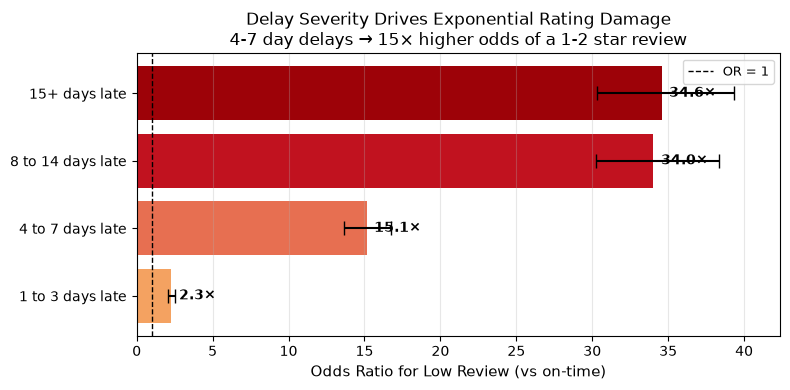

Saved: outputs/model_a_delay_bucket_robustness.png


In [10]:
# Plot delay buckets
fig, ax = plt.subplots(figsize=(8, 4))
labels  = rob_buckets['Delay_Bucket']
ors     = rob_buckets['Odds_Ratio']
cis_lo  = ors - rob_buckets['CI_Lower_95']
cis_hi  = rob_buckets['CI_Upper_95'] - ors
colors  = ['#f4a261','#e76f51','#c1121f','#9d0208']

bars = ax.barh(labels, ors, xerr=[cis_lo, cis_hi],
               color=colors, capsize=5, error_kw={'elinewidth':1.5})
ax.axvline(1, color='black', linestyle='--', linewidth=1, label='OR = 1')
for bar, val in zip(bars, ors):
    ax.text(val + 0.5, bar.get_y() + bar.get_height()/2,
            f'{val:.1f}×', va='center', fontsize=10, fontweight='bold')

ax.set_xlabel('Odds Ratio for Low Review (vs on-time)', fontsize=11)
ax.set_title('Delay Severity Drives Exponential Rating Damage\n'
             '4-7 day delays → 15× higher odds of a 1-2 star review', fontsize=12)
ax.legend(fontsize=9); ax.grid(axis='x', alpha=0.3)
ax.set_xlim(0, rob_buckets['CI_Upper_95'].max() + 3)
plt.tight_layout()
plt.savefig('../outputs/model_a_delay_bucket_robustness.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: outputs/model_a_delay_bucket_robustness.png")


## 8. Model A Summary

| Metric | Value |
|:---|:---|
| **Training observations** | 76,636 |
| **Test observations** | 19,159 |
| **Positive rate (is_late)** | 8.1 % |
| **ROC-AUC (test)** | **0.7740** |
| **PR-AUC (test)** | 0.3145 |
| **McFadden Pseudo R²** | 0.1685 |
| **Max VIF** | 5.15 (cust_state_SP only) |
| **Convergence** | Yes (MLE, 200 iterations) |

### Top findings from Model A

| Factor | Odds Ratio | 95 % CI | Plain-English interpretation |
|:---|:---:|:---|:---|
| `seller_handling_days` | **2.22** | [2.17, 2.28] | Each extra std-dev of handling time **doubles** late odds |
| `log_distance` | 1.50 | [1.42, 1.58] | Longer routes add 50 % to late odds |
| `log_weight` | 1.06 | [1.01, 1.11] | Heavier parcels are marginally riskier |
| `estimated_days` | **0.27** | [0.25, 0.28] | Each extra buffer day **cuts** late odds by 73 % |
| `same_state` | 0.61 | [0.54, 0.69] | Intra-state orders are 39 % less likely to be late |
| `cust_state_PR` | 0.20 | [0.16, 0.24] | Paraná customers see the lowest late odds (carrier efficiency) |
| `cust_state_SP` | 0.21 | [0.18, 0.25] | São Paulo benefits from dense fulfillment hub proximity |
| `purchase_month` | 0.75 | [0.73, 0.77] | Later months (trend) associated with improving performance |

> **Association, not causation.** These coefficients show statistical association with lateness,  
> not confirmed causal pathways. See Limitations in `README.md`.


In [11]:
print("✓ Notebook 03_model_late.ipynb complete — all outputs saved to outputs/")


✓ Notebook 03_model_late.ipynb complete — all outputs saved to outputs/
